# Módulo 13 — Fundamentos da Descoberta de Dados
**Projeto:** análise estatística e visual de produtos de um supermercado chileno · Curso de Ciência de Dados (EBAC)
**Autor:** Lucas Farias Epitácio de Almeida

**Objetivo:** entender como os preços e os descontos se distribuem entre as categorias de produtos, usando medidas de tendência central, dispersão e visualizações.

| Coluna | Descrição |
|---|---|
| `title` | Nome do produto |
| `Marca` | Marca |
| `Preco_Normal` | Preço sem desconto (0 = produto em promoção) |
| `Preco_Desconto` | Preço após desconto |
| `Preco_Anterior` | Preço antes do desconto |
| `Desconto` | Valor do desconto (CLP) |
| `Categoria` | Categoria (em espanhol) |

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
COR = '#2E86C1'
os.makedirs('resultados', exist_ok=True)

## Leitura e verificação dos dados

In [2]:
df = pd.read_csv('base_supermercado.csv')
print(f'{df.shape[0]} linhas x {df.shape[1]} colunas')
print('Valores nulos:', df.isna().sum().sum())
df.head()

1107 linhas x 7 colunas
Valores nulos: 0


,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos


### Atenção: `Preco_Normal = 0` não significa produto grátis
Nos produtos em promoção, o preço cheio fica em `Preco_Anterior` e `Preco_Normal` aparece como 0. Calcular a média com esses zeros puxa as estatísticas para baixo e distorce a comparação entre categorias.

In [3]:
zeros = (df['Preco_Normal'] == 0)
print(f'Produtos com Preco_Normal = 0: {zeros.sum()} ({zeros.mean():.1%})')
df.loc[zeros, ['title', 'Preco_Normal', 'Preco_Desconto', 'Preco_Anterior', 'Desconto']].head()

Produtos com Preco_Normal = 0: 294 (26.6%)


,title,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto
813,"Pañal adulto Pants G-XG 16 un,",0,13899,0,0
814,"Pañal adulto Pants P-M 16 un,",0,13899,0,0
815,Pizza americana pepperoni congelada 660 g,0,5990,0,0
816,Pizza americana deluxe congelada 660 g,0,5990,0,0
817,Pizza americana congelada veggies 745 g,0,5990,0,0


**Tratamento:** crio a coluna `Preco_Cheio`, que usa `Preco_Normal` quando existe e `Preco_Anterior` nos produtos em promoção. Linhas em que nenhum dos dois está preenchido ficam como ausentes (NaN) e saem dos cálculos. Na prática isso remove 176 produtos sem nenhum preço de referência. Assim todas as estatísticas comparam o mesmo conceito: o preço de tabela do produto.

In [4]:
import numpy as np
df['Preco_Cheio'] = df['Preco_Normal'].where(df['Preco_Normal'] > 0, df['Preco_Anterior'])
df['Preco_Cheio'] = df['Preco_Cheio'].replace(0, np.nan)
df['Tem_Desconto'] = df['Desconto'] > 0
print('Sem preço de referência (excluídos):', df['Preco_Cheio'].isna().sum())

Sem preço de referência (excluídos): 176


## 1. Média e mediana do preço por categoria
A média é sensível a valores extremos; a mediana não. Comparar as duas mostra o formato da distribuição: média > mediana indica cauda à direita (poucos produtos caros puxando a média).

In [5]:
def resumo_por_categoria(dados, coluna):
    """Calcula estatísticas descritivas de uma coluna numérica por categoria.

    Parâmetros
    ----------
    dados : pd.DataFrame com a coluna 'Categoria'.
    coluna : str, nome da coluna numérica a resumir.

    Retorna
    -------
    pd.DataFrame com n, média, mediana, desvio padrão, coeficiente de variação
    e a razão média/mediana, ordenado pelo desvio padrão.
    """
    r = dados.groupby('Categoria')[coluna].agg(n='count', media='mean', mediana='median', desvio='std')
    r['cv_%'] = r['desvio'] / r['media'] * 100
    r['media_vs_mediana'] = np.where(r['media'] > r['mediana'], 'acima', 'abaixo')
    r['razao_media_mediana'] = r['media'] / r['mediana']
    return r.sort_values('desvio', ascending=False).round(2)

resumo = resumo_por_categoria(df, 'Preco_Cheio')
resumo.to_csv('resultados/resumo_precos_categoria.csv')
resumo

,n,media,mediana,desvio,cv_%,media_vs_mediana,razao_media_mediana
Categoria,,,,,,,
lacteos,363,"3,046.72","1,759.00","4,222.27",138.58,acima,1.73
belleza-y-cuidado-personal,189,"2,983.16","2,690.00","1,934.18",64.84,acima,1.11
congelados,224,"3,190.21","3,029.00","1,810.67",56.76,acima,1.05
frutas,19,"1,724.47","1,195.00","1,639.15",95.05,acima,1.44
instantaneos-y-sopas,37,"1,179.27",689.00,"1,276.22",108.22,acima,1.71
comidas-preparadas,40,"3,948.30","3,890.00","1,252.84",31.73,acima,1.01
verduras,59,"1,457.14","1,250.00",972.23,66.72,acima,1.17


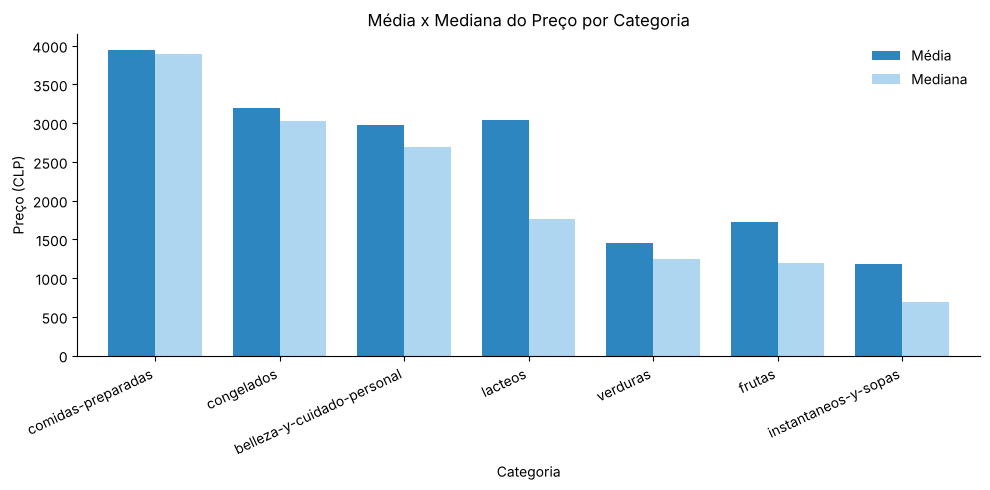

In [6]:
def grafico_media_mediana(resumo, titulo):
    """Barras agrupadas comparando média e mediana por categoria.

    Parâmetros
    ----------
    resumo : DataFrame com colunas 'media' e 'mediana', índice = categoria.
    titulo : str, título do gráfico.
    """
    ordem = resumo.sort_values('mediana', ascending=False)
    ax = ordem[['media', 'mediana']].plot.bar(color=[COR, '#AED6F1'], width=0.75)
    ax.set_title(titulo); ax.set_xlabel('Categoria'); ax.set_ylabel('Preço (CLP)')
    ax.legend(['Média', 'Mediana'], frameon=False)
    plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

grafico_media_mediana(resumo, 'Média x Mediana do Preço por Categoria')

**Leitura:**
- **Todas as categorias têm média acima da mediana**: distribuições assimétricas à direita (poucos produtos caros puxam a média).
- A diferença é grande em **instantaneos-y-sopas** (média ≈ 1,7× a mediana), **lacteos** (≈ 1,7×) e **frutas** (≈ 1,4×).
- Em **comidas-preparadas** e **congelados** média e mediana quase coincidem: distribuição mais simétrica.
- Sem o tratamento dos zeros, comidas-preparadas parecia ter média *abaixo* da mediana; essa conclusão era um efeito do dado mal interpretado.

## 2. Desvio padrão por categoria
Além do desvio padrão (em CLP), uso o **coeficiente de variação (CV)**, que divide o desvio pela média e permite comparar a dispersão de categorias com níveis de preço diferentes.

In [7]:
resumo[['n', 'media', 'mediana', 'desvio', 'cv_%']]

,n,media,mediana,desvio,cv_%
Categoria,,,,,
lacteos,363,"3,046.72","1,759.00","4,222.27",138.58
belleza-y-cuidado-personal,189,"2,983.16","2,690.00","1,934.18",64.84
congelados,224,"3,190.21","3,029.00","1,810.67",56.76
frutas,19,"1,724.47","1,195.00","1,639.15",95.05
instantaneos-y-sopas,37,"1,179.27",689.00,"1,276.22",108.22
comidas-preparadas,40,"3,948.30","3,890.00","1,252.84",31.73
verduras,59,"1,457.14","1,250.00",972.23,66.72


**Leitura:** **lacteos** tem o maior desvio (≈ 4.200 CLP) e também o maior CV (≈ 139%). É justamente a categoria com a maior distância entre média e mediana. Nas categorias mais dispersas a média deixa de representar o produto típico, e a **mediana passa a ser a medida mais adequada**.

## 3. Boxplot da categoria com maior desvio

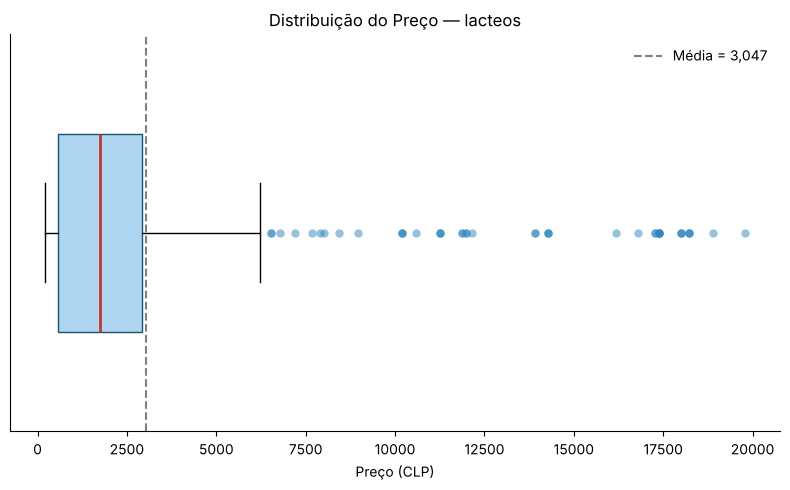

Q1 = 572 | Mediana = 1,759 | Q3 = 2,914 | limite superior = 6,428
Outliers: 43 de 363 produtos (11.8%)


In [8]:
cat_maior_desvio = resumo.index[0]
serie = df.loc[df['Categoria'] == cat_maior_desvio, 'Preco_Cheio'].dropna()

q1, q3 = serie.quantile([0.25, 0.75]); iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
outliers = serie[serie > lim_sup]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(serie, orientation='horizontal', patch_artist=True, widths=0.5,
           boxprops=dict(facecolor='#AED6F1', color='#1A5276'),
           medianprops=dict(color='#C0392B', linewidth=2),
           flierprops=dict(marker='o', markerfacecolor=COR, alpha=0.5, markeredgecolor='none'))
ax.axvline(serie.mean(), ls='--', color='gray', label=f'Média = {serie.mean():,.0f}')
ax.set_title(f'Distribuição do Preço — {cat_maior_desvio}')
ax.set_xlabel('Preço (CLP)'); ax.set_yticks([]); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(f'Q1 = {q1:,.0f} | Mediana = {serie.median():,.0f} | Q3 = {q3:,.0f} | limite superior = {lim_sup:,.0f}')
print(f'Outliers: {len(outliers)} de {len(serie)} produtos ({len(outliers)/len(serie):.1%})')

In [9]:
# Quais são os produtos outliers?
df.loc[outliers.index, ['title', 'Marca', 'Preco_Cheio']].sort_values('Preco_Cheio', ascending=False).head(10)

,title,Marca,Preco_Cheio
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,"19,788.00"
1106,Leche en Polvo Nido Forticrece Sin lactosa 1440g,Nido,"18,899.00"
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,"18,228.00"
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,"18,228.00"
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,"18,228.00"
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,"17,988.00"
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,"17,988.00"
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,"17,988.00"
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,"17,388.00"
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,"17,388.00"


**Leitura:** metade dos lácteos custa menos de ~1.760 CLP, 75% custam até ~2.900 CLP, e a caixa (Q1–Q3) é estreita, mas há **43 outliers** (≈ 12% da categoria) acima de ~6.400 CLP. A tabela mostra que eles não são erros de digitação: são **packs com várias unidades** (12 litros de leite, por exemplo). A distribuição é fortemente **assimétrica à direita**.

Implicação: para analisar preço, valeria separar packs de unidades (ou calcular preço por litro/unidade) antes de comparar produtos.

## 4. Média de desconto por categoria
O enunciado pede a média de descontos. Mostro duas leituras, porque respondem perguntas diferentes:
- **Média geral** (inclui produtos sem desconto): quanto se economiza, em média, num produto qualquer da categoria.
- **Média entre os produtos em promoção**: quando há desconto, de quanto ele é.

In [10]:
desc = df.groupby('Categoria').agg(
    media_geral=('Desconto', 'mean'),
    pct_em_promocao=('Tem_Desconto', 'mean'))
desc['media_quando_ha_desconto'] = df[df['Tem_Desconto']].groupby('Categoria')['Desconto'].mean()
desc['pct_em_promocao'] *= 100
desc = desc.fillna(0).round(1).sort_values('media_geral', ascending=False)
desc.to_csv('resultados/descontos_categoria.csv')
desc

,media_geral,pct_em_promocao,media_quando_ha_desconto
Categoria,,,
congelados,154.00,25.50,603.30
belleza-y-cuidado-personal,123.10,18.00,684.10
comidas-preparadas,43.50,8.70,500.00
lacteos,17.40,2.50,707.50
frutas,0.00,0.00,0.00
instantaneos-y-sopas,0.00,0.00,0.00
verduras,0.00,0.00,0.00


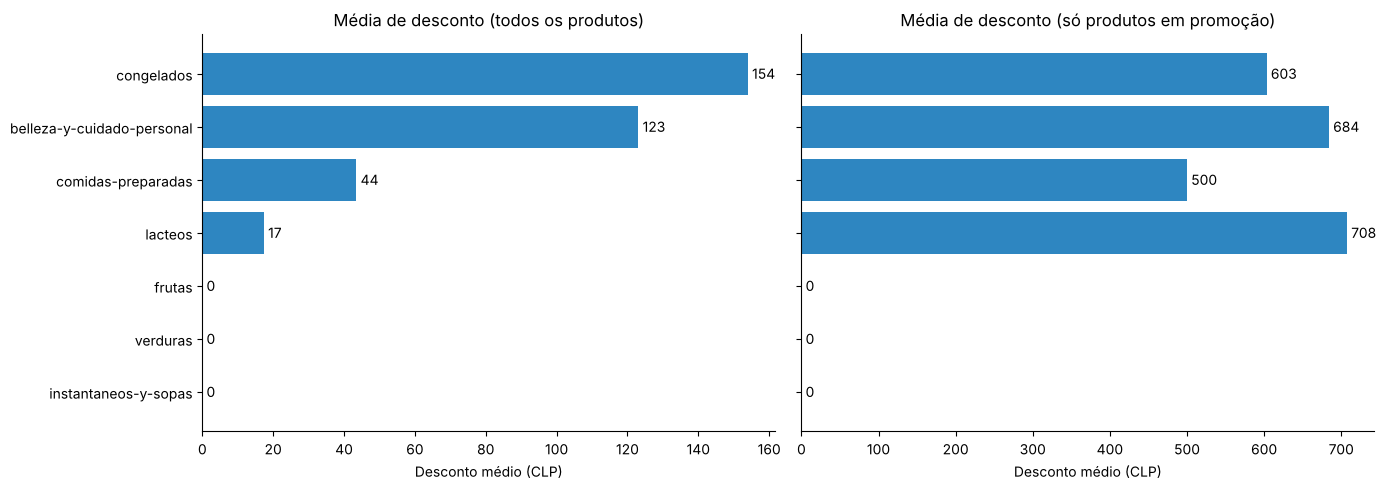

In [11]:
def grafico_barras(serie, titulo, rotulo_y, ax):
    """Barras horizontais com rótulo de valor em cada barra.

    Parâmetros
    ----------
    serie : pd.Series, índice = categorias, valores numéricos.
    titulo, rotulo_y : str, textos do gráfico.
    ax : eixo matplotlib onde desenhar.
    """
    s = serie.sort_values()
    barras = ax.barh(s.index, s.values, color=COR)
    ax.bar_label(barras, fmt='{:,.0f}', padding=3)
    ax.set_title(titulo); ax.set_xlabel(rotulo_y)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
grafico_barras(desc['media_geral'], 'Média de desconto (todos os produtos)', 'Desconto médio (CLP)', axes[0])
grafico_barras(desc['media_quando_ha_desconto'], 'Média de desconto (só produtos em promoção)', 'Desconto médio (CLP)', axes[1])
plt.tight_layout(); plt.show()

**Leitura:** **congelados** (25% dos produtos em promoção) e **belleza-y-cuidado-personal** (18%) lideram a média geral porque concentram as promoções. Já **lacteos**, quando tem desconto, oferece o maior valor médio (~710 CLP), mas só 2,5% dos lácteos estão em promoção — e essa média é puxada por um único leite em pó Nido com 4.349 CLP de desconto. **frutas, verduras e instantâneos** não tiveram nenhum desconto na base.

## 5. Treemap interativo: desconto por categoria e marca
O treemap mostra a hierarquia Categoria → Marca. O tamanho de cada retângulo é o **número de produtos em promoção** e a cor é a **média de desconto**. Uso a contagem como tamanho porque somar médias de marcas diferentes não tem significado.

In [12]:
tm = (df[df['Tem_Desconto']]
      .groupby(['Categoria', 'Marca'])
      .agg(Media_Desconto=('Desconto', 'mean'), Produtos=('Desconto', 'size'))
      .round(1).reset_index())
tm.to_csv('resultados/desconto_categoria_marca.csv', index=False)

fig = px.treemap(tm, path=[px.Constant('Todas'), 'Categoria', 'Marca'],
                 values='Produtos', color='Media_Desconto',
                 color_continuous_scale='Blues',
                 hover_data={'Media_Desconto': ':,.0f', 'Produtos': True},
                 title='Média de Desconto por Categoria e Marca')
fig.update_traces(texttemplate='%{label}<br>%{color:,.0f} CLP')
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10), coloraxis_colorbar_title='Desconto (CLP)')
fig.write_html('resultados/treemap_descontos.html')
fig.show()

**Leitura:** dentro de belleza-y-cuidado-personal, **Dove**, **Dove Men** e **Pantene** têm os maiores descontos médios. Em congelados, **Magnum** se destaca (~955 CLP em 4 produtos). Em lácteos, o retângulo mais escuro é **Nido**, mas com um único produto — médias com n = 1 merecem cautela.

> No GitHub o gráfico interativo não aparece. A versão interativa está salva em `resultados/treemap_descontos.html`.

## Conclusões
1. **Cuidado com zeros que significam ausência de dado.** 27% dos produtos tinham `Preco_Normal = 0`; tratar isso mudou médias e medianas e desfez a falsa assimetria de comidas-preparadas.
2. **Preços assimétricos à direita** em todas as categorias: a mediana representa melhor o produto típico.
3. **Lácteos** é a categoria mais heterogênea (maior desvio e CV), por misturar unidades e packs.
4. **Promoções se concentram** em congelados e cuidados pessoais; hortifrúti e instantâneos não tinham desconto.

**Próximos passos:** calcular preço por unidade/litro para comparar packs e unidades de forma justa.